# 딥러닝 ① 요약본

## 1. 합성곱 신경망(CNN)

### 1-1. 픽셀과 채널

**1) 픽셀**
- 이미지 데이터를 구성하는 가장 기본적인 단위로, 특정 위치의 색상 또는 밝기 정보를 가짐
- 흑백 이미지 크기 = (세로 픽셀 수 × 가로 픽셀 수)의 2차원 배열 (예: 28 × 28)
- 픽셀 값은 일반적으로 0~255 범위 (0 = 검은색, 255 = 흰색)

**2) 채널**
- 이미지의 색상 정보를 구성하는 각각의 데이터 층
- 하나의 이미지에서 색상이나 밝기 정보를 구분하여 저장하는 단위

**3) 색공간**
- 이미지를 구성하는 색상을 숫자로 표현하는 방법이나 체계

| 색공간 | 표현 방식 | 채널 수 | 저장 형태 |
|---|---|---|---|
| 그레이 스케일 | 색상 구분 없이 밝기 정보만 사용 (0~255) | 1 | (H × W), 예: (28 × 28) |
| RGB | Red, Green, Blue 세 색상 값의 조합 (각 0~255) | 3 | (H × W × 3), 예: (28 × 28 × 3) |
| HSV | 색상(Hue), 채도(Saturation), 명도(Value) 기준 | 3 | - |

### 1-2. CNN의 개념

**1) 이미지 인식 방법의 차이**
- 사람: 모든 픽셀을 살피지 않고, 눈/귀/코 등 물체를 구분하는 데 중요한 영역과 특징에 집중
- 컴퓨터: 이미지를 픽셀 단위로 구분하고 각 픽셀의 숫자 정보를 처리
> 컴퓨터에게 이미지는 수많은 픽셀 값이 모여 만들어진 숫자 데이터

**2) 픽셀 정보를 그냥 학습하면 생기는 문제점**
- 이미지를 1차원 배열로 펼치면 각 픽셀의 위치(공간 정보)가 사라짐
- 서로 가까이 있는 픽셀들의 관계가 모델에 직접 반영되지 않아, 주변 픽셀들이 모여 만드는 특징(눈, 귀 등)을 학습하기 어려움

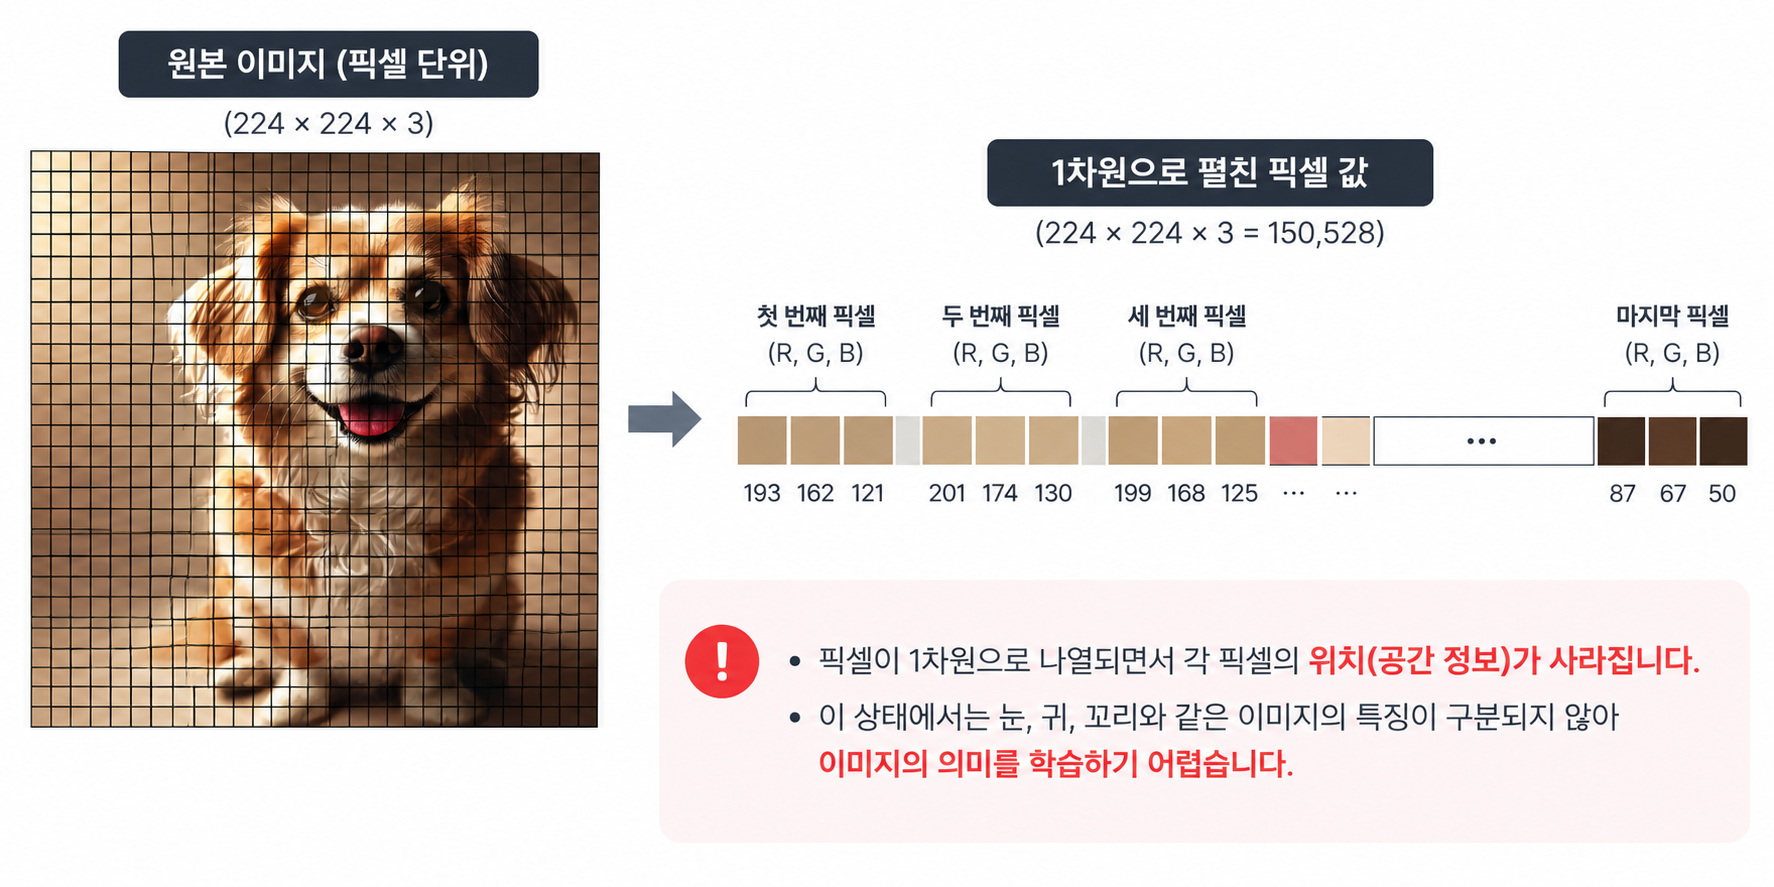

**3) MLP와 CNN의 구조 비교**
- MLP = FC Layer + … + FC Layer
   - 2차원 이미지를 1차원 배열로 펼친 뒤 FC Layer에 입력
- CNN = (Conv + Pool) + … + Flatten + FC Layer + … + FC Layer
   - 공간적 특징을 유지하면서 Conv와 Pool을 반복하여 특징 추출 → Flatten → FC Layer로 분류

> MLP와 CNN의 가장 큰 차이:
> <br> FC Layer 적용 전 Conv와 Pool을 이용해 이미지의 특징을 학습하는 과정이 추가됨

**4) CNN 모델의 전체 구조**

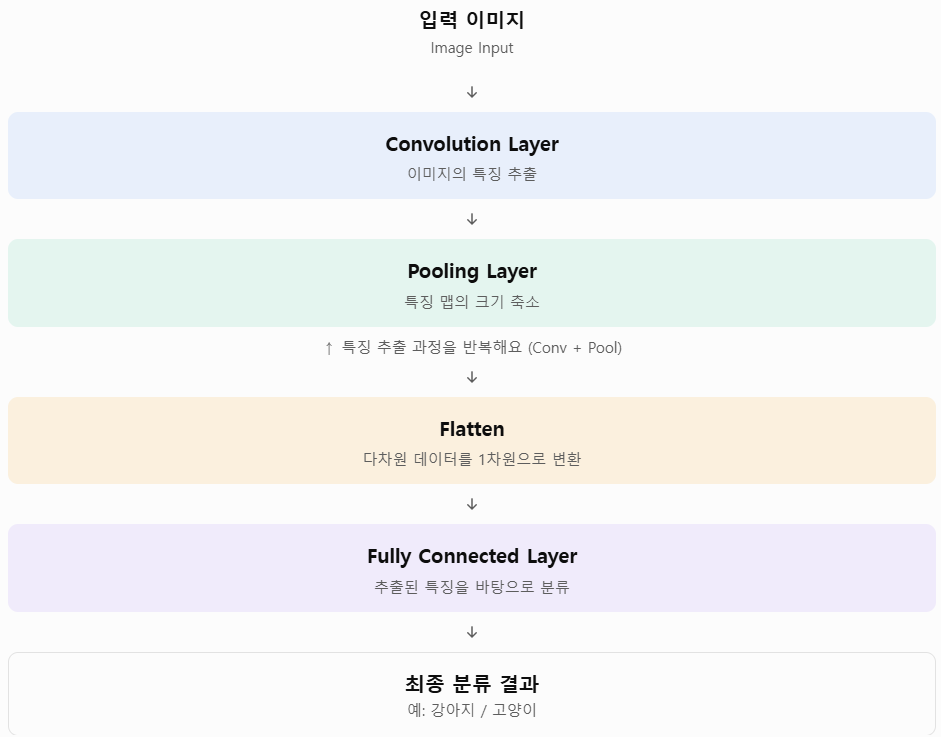

| 구분 | Layer | 역할 |
|---|---|---|
| 특징 추출 (Feature Learning) | Convolution Layer | 필터(Kernel)를 이동시키며 모서리, 질감, 형태 등 특징 추출 |
| | Pooling Layer | 특징 맵의 크기를 줄이고 중요한 특징을 유지하여 연산량 감소 |
| - | Flatten | 다차원 특징 맵을 FC Layer에 입력할 수 있도록 1차원 배열로 변환 |
| 분류 (Classification) | Fully Connected Layer | 추출된 특징을 종합하여 최종 클래스 분류 |

> (Conv + Pool)을 반복하여 이미지의 공간적 특징을 추출한 후 FC Layer를 통해 분류하는 것이 CNN의 핵심 구조


### 1-3. 왜 이미지 처리에 MLP가 아닌 CNN을 사용할까?

**1) 이미지 데이터의 구조**
- 흑백 이미지: 각 픽셀에 하나의 밝기 값 > H × W 형태의 2차원 배열
- 컬러(RGB) 이미지: 각 픽셀에 3개의 색상 값 > H × W × 3 형태의 3차원 배열
- 대표 데이터셋: MNIST (0~9 손글씨 숫자, 28 × 28 흑백 이미지)
- 정형 데이터는 각 열이 독립적인 의미를 갖지만, 이미지는 픽셀들이 가로·세로로 연결되어 있어 주변 픽셀 간의 관계와 위치 정보가 중요함

> 픽셀 간의 공간적 관계와 이미지 구조를 유지하면서 특징을 학습할 수 있는 모델이 필요 => CNN

**2) MLP의 한계와 CNN의 해결 방식**

| 한계 | MLP의 문제 | CNN의 해결 방식 |
|---|---|---|
| 위치, 크기, 회전 변화에 취약 (Translation Variant) | 픽셀 위치별 가중치를 학습 > 숫자가 조금만 이동해도 입력이 크게 달라져 인식 실패 | 동일한 필터를 여러 위치에 반복 적용 + Pooling > 특징이 어디에 있든 탐지 |
| 파라미터 폭발 (Parameter Explosion) | 완전연결 구조로 가중치 수가 픽셀 수만큼 생성 > 과적합 가능성 상승, 학습 속도 느림 | 작은 영역에만 필터를 적용하는 부분 연결 구조 + 가중치 공유 > 이미지가 커져도 파라미터 수가 크게 늘지 않음 |
| 공간 정보 손실 (Loss of Spatial Info) | Flatten으로 1차원 벡터화 > 2차원 공간 구조가 유지되지 않음 | H × W × C 다차원 구조를 유지한 채 공간적 특징을 먼저 학습한 후 Flatten |

**MLP와 CNN의 파라미터 수 비교 예시**
| 구분 | 구조 | 가중치 및 편향 수 |
|---|---|---|
| MLP | 1,000,000개 입력 × 10,000개 노드 | 약 100억 개 |
| CNN | 3 × 3 필터 32개 (흑백 이미지 기준) | 320개 |


### 1-4. 합성곱(Convolution)과 풀링(Pooling)

**1) Convolution Layer**
- 입력 이미지 전체를 일정한 크기의 필터로 훑으면서 특징을 추출하고 학습하는 계층
- 필터는 수직선, 수평선, 모서리, 질감 등 특정 패턴을 감지하는 역할

- 연산 과정
   - ① 필터가 이미지 왼쪽 위에서 시작해 정해진 간격만큼 오른쪽·아래로 슬라이딩
   - ② 각 위치에서 픽셀 값과 필터 가중치를 요소별로 곱한 후 합계 계산
   - ③ 결과를 Feature Map의 해당 위치에 저장

- 커널(Kernel)과 필터(Filter)의 차이

| 구분 | 정의 | 특징 |
|---|---|---|
| 커널 | 특정 패턴을 추출하기 위한 2차원 가중치 행렬 | 실제 연산이 일어나는 가장 기본 단위 (예: 3 × 3 = 9개 가중치) |
| 필터 | 여러 개의 커널이 모인 집합 | 다채널 입력에서 차이가 명확. RGB 이미지는 채널별 커널 3개를 묶은 것이 하나의 필터 |

- Feature Map
   - Convolution 연산을 통해 생성되는 결과 데이터
   - 필터가 특정 특징에 반응할수록 해당 위치의 값이 커짐
   - Feature Map의 개수 = 사용하는 필터의 개수

**2) Padding**
- Convolution 연산 전 입력 이미지의 가장자리에 추가 픽셀을 삽입하는 방법 (주로 0을 추가하는 Zero Padding)
- Padding이 없으면 가장자리 영역에 필터가 적용되는 횟수가 상대적으로 적어짐

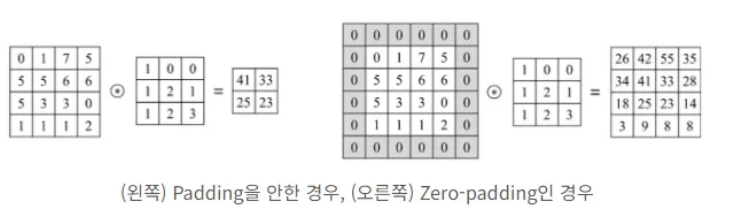

> 이미지의 공간적 크기를 유지하면서 가장자리의 특징까지 학습할 수 있도록 하는 역할

**3) Stride (보폭)**
- 필터가 한 번에 이동하는 간격


| 구분 | 이동 | 특징 | Feature Map 크기 (7×7 입력, 3×3 필터) |
|---|---|---|---|
| Stride = 1 | 한 칸씩 | 여러 위치를 세밀하게 확인 → 세부 특징 추출에 유리 | 5 × 5 (상대적으로 큼) |
| Stride = 2 | 두 칸씩 | 일부 위치를 건너뛰며 연산 → 연산량 감소 | 3 × 3 (상대적으로 작음) |

> Stride는 특징 추출의 세밀함과 연산 효율 사이를 조절하는 요소

**4) Pooling**
- 일정 크기의 영역(일반적으로 2 × 2)의 값을 하나의 값으로 요약
- 작은 위치 변화에 대한 민감도를 낮춰 특징을 더 안정적으로 인식하도록 함
- Pooling이 없으면 필터가 엄격하게 특정 픽셀 위치에서만 패턴을 찾아, 객체가 미세하게 이동해도 동일한 특징으로 인식하지 못함

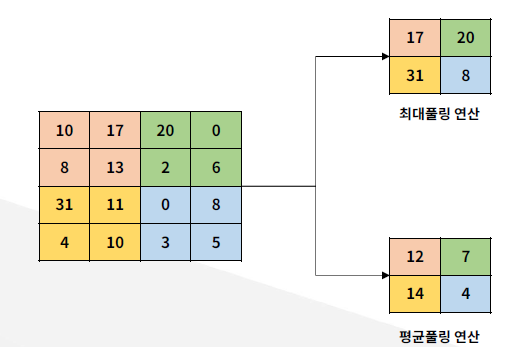

- 종류
   - Max Pooling: 영역 내 가장 큰 값 선택
   - Average Pooling: 영역 내 모든 값의 평균 계산

- 장단점

| 구분 | 내용 |
|---|---|
| 장점 | 차원 축소로 계산량 감소 / 위치 변화에 대한 강건성 / 과적합 방지에 도움 / 노이즈 영향 완화 |
| 단점 | 정보 소실의 위험 / 정확한 위치 정보 감소 (객체 경계 등 세밀한 위치가 중요한 작업에서 문제) |

**5) CNN 구조 정리**

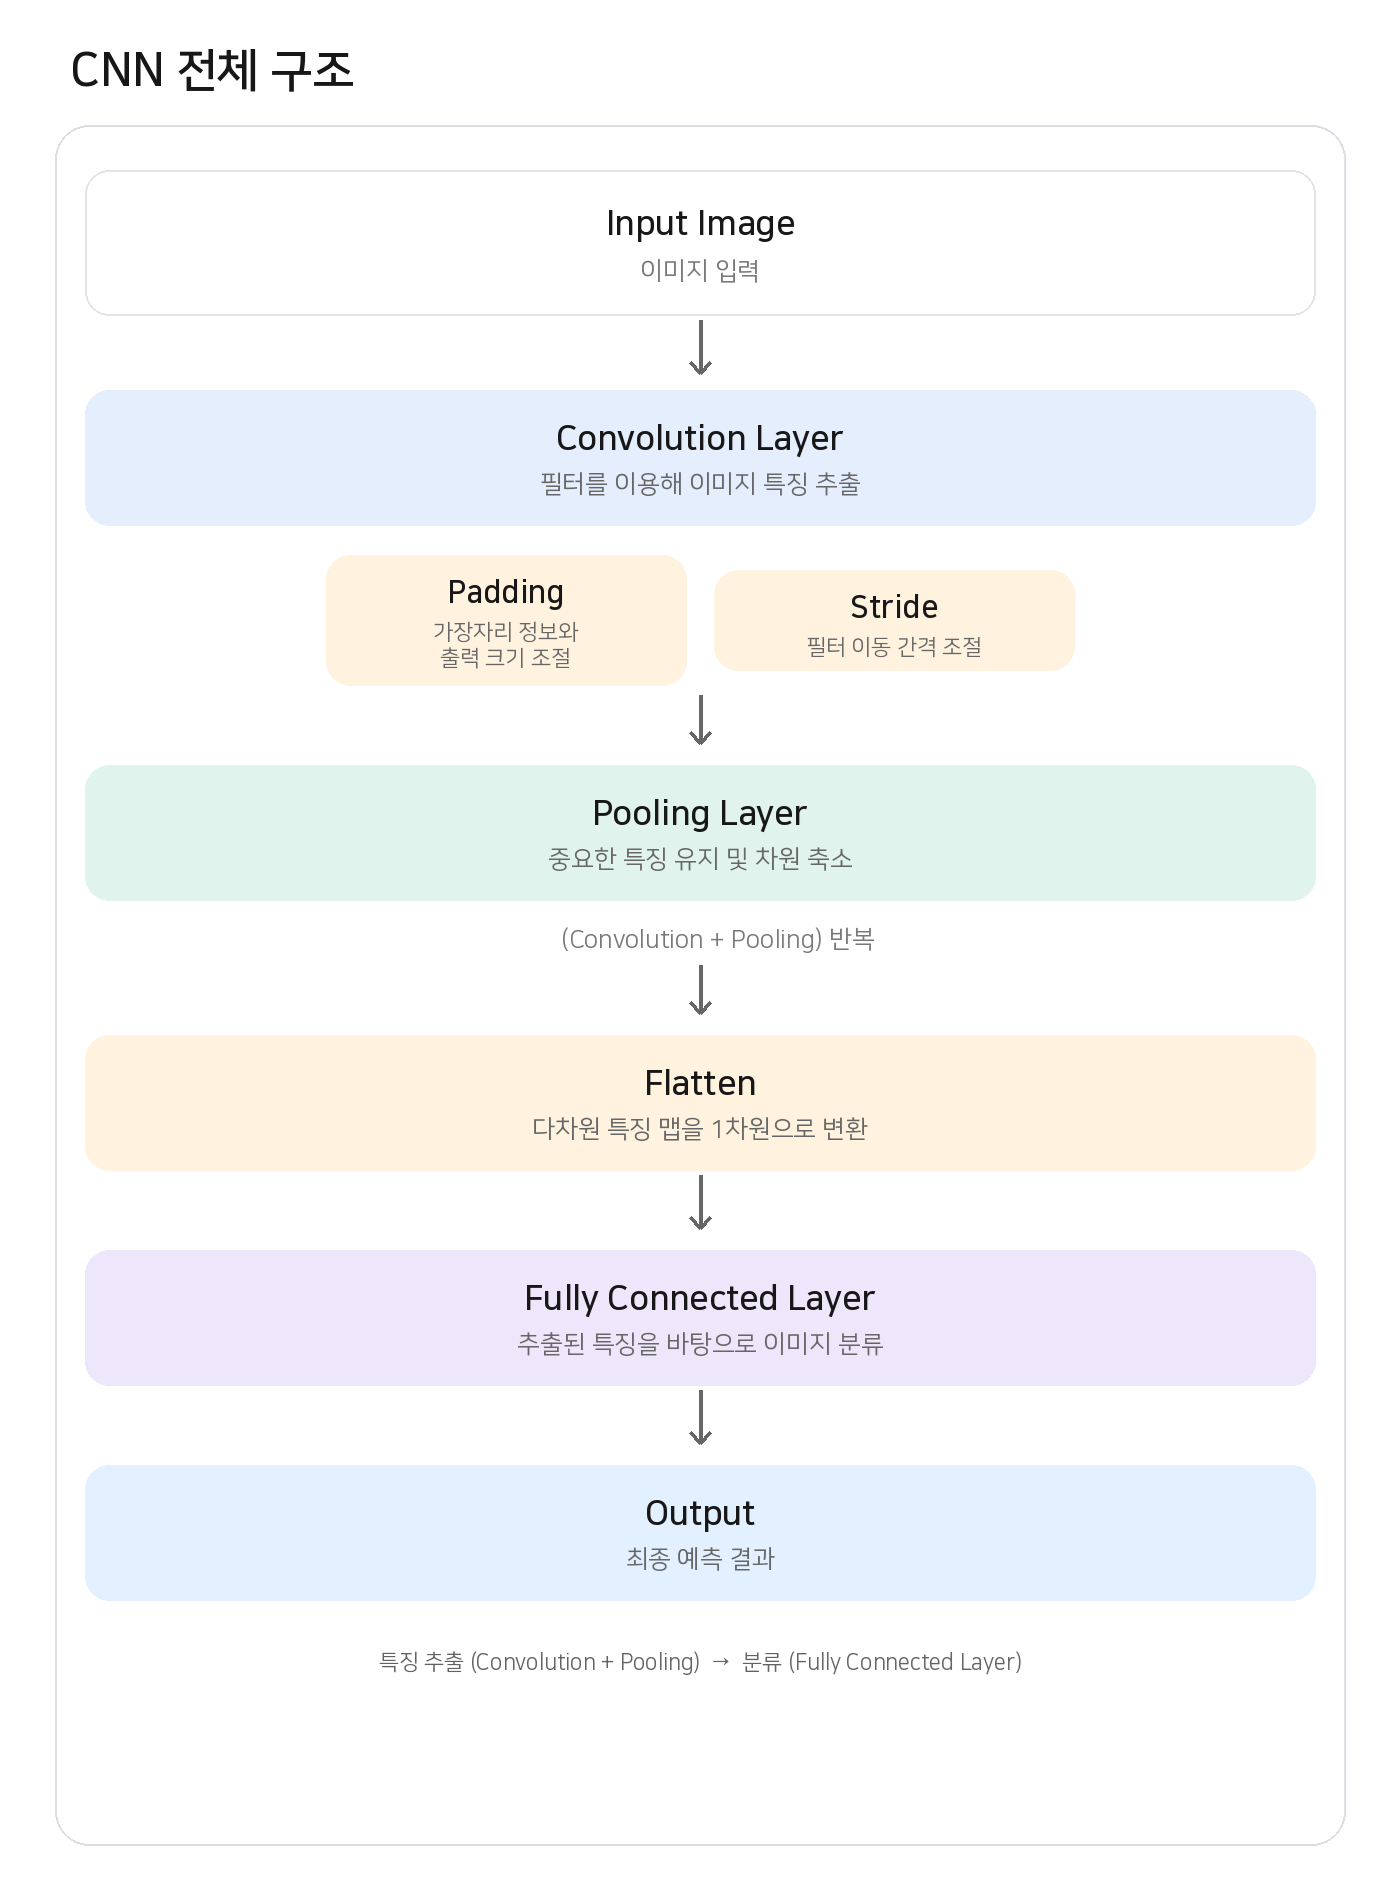

- Convolution Layer와 Pooling은 특징 추출을 담당
- Padding과 Stride는 출력 크기와 정보 보존 정도를 조절하는 하이퍼파라미터

### 1-5. 대표적인 CNN 아키텍처

**1) AlexNet (2012)**

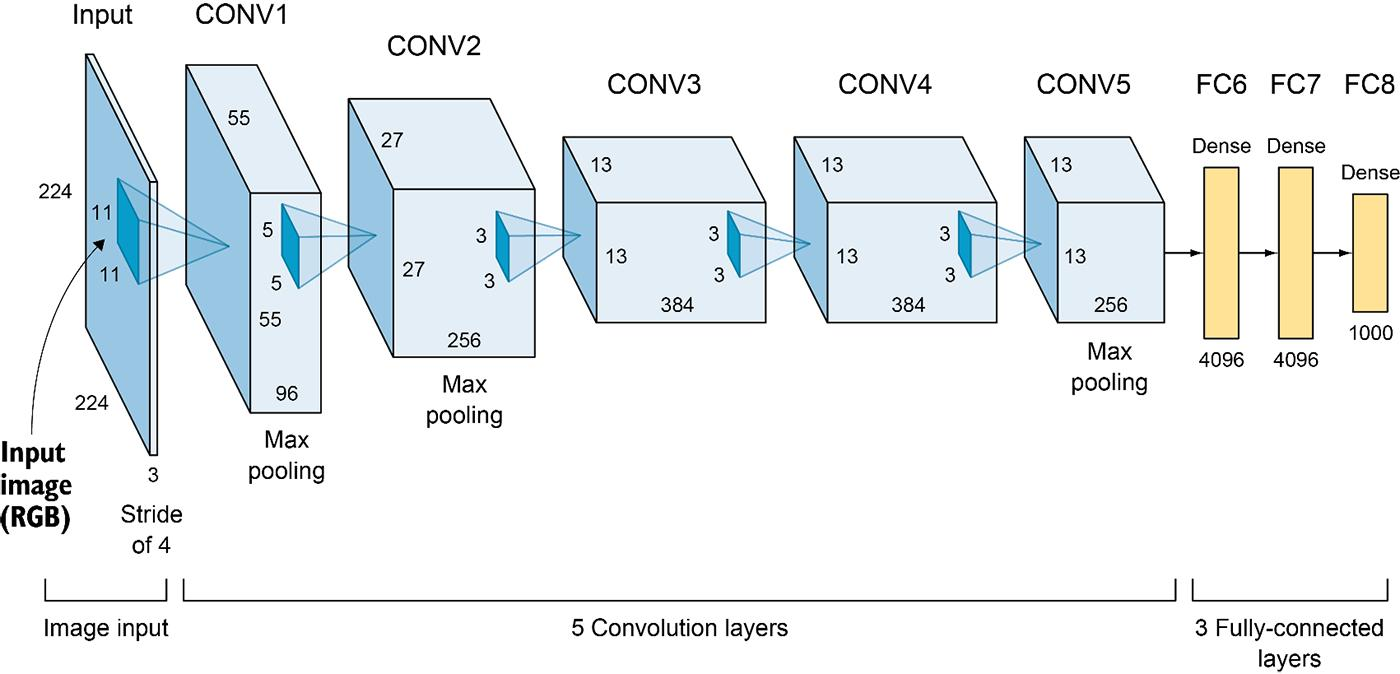

- 2012년 ImageNet 대회(ILSVRC)에서 뛰어난 성과를 거둔 모델로, 딥러닝의 가능성을 보여줌
- 구조: 총 8개 학습 계층 (Convolution Layer 5개 + FC Layer 3개), ReLU와 Max Pooling 적용
- 5가지 혁신 기술
   - ReLU: Tanh 대신 사용해 기울기 소실 해결, 학습 속도 6배 이상 향상
   - 다중 GPU 병렬 연산: GPU 2개를 병렬로 연결해 네트워크를 상·하단으로 분할 학습
   - 드롭아웃: 과적합 방지를 위해 FC 계층 뉴런 일부(예: 50%)를 무작위로 끄고 학습
   - 데이터 증강: Crop, 좌우 반전, RGB 채널 값 변경으로 훈련 데이터 증가
   - LRN: 강하게 활성화된 뉴런 주변을 감쇄 (최근에는 Batch Normalization으로 대체)

**2) VGGNet (2014)**

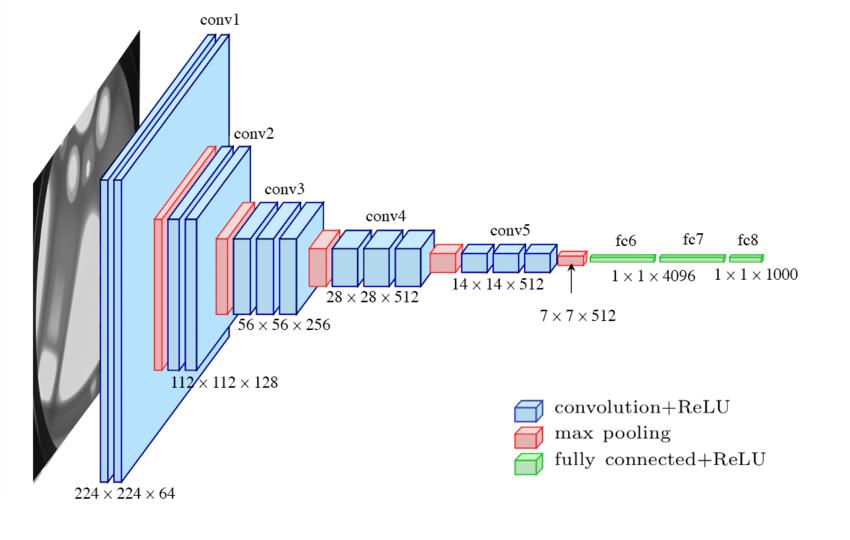

- 옥스퍼드대 연구팀이 개발, 네트워크의 깊이를 늘리면 성능이 향상될 수 있음을 보여줌 (VGG16, VGG19 - 숫자는 학습 가능한 계층 수)
- 구조: VGG16 = Convolution Layer 13개 + FC Layer 3개, 3 × 3 필터 반복 + 중간중간 Max Pooling
- 특징: 작은 필터의 반복 사용 / 깊은 네트워크 / 일관된 구조
- AlexNet 대비 발전: 큰 필터·적은 층 대신 3 × 3 필터를 반복 적용해 더 깊게 구성 > 단순한 특징부터 복잡한 형태까지 세밀하게 학습

**3) ResNet (2015)**

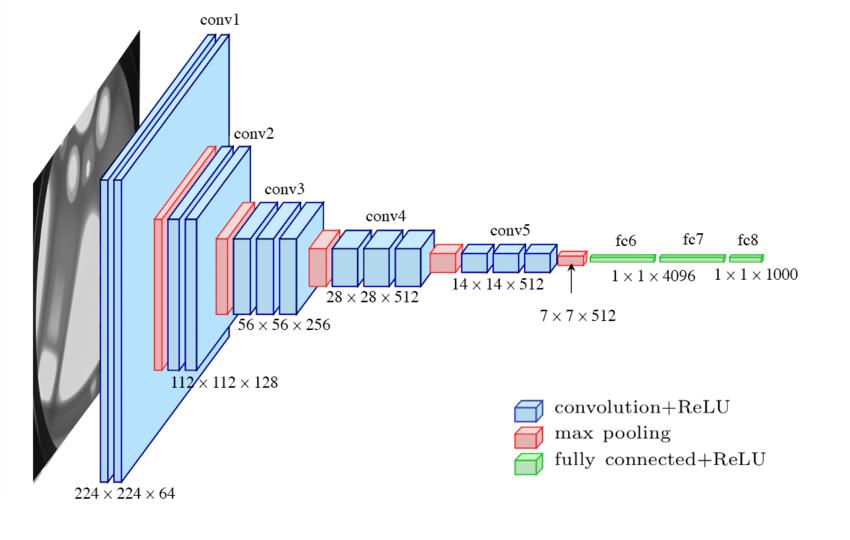

- 깊은 신경망을 효과적으로 학습하기 위해 잔차 연결(Residual Connection)을 도입한 모델
- 핵심: 잔차 학습(Residual Learning)과 지름길(Shortcut)
   - Skip Connection: 입력 정보를 중간 계층을 거치지 않고 뒤쪽 계층으로 직접 전달
   - 계층을 통과한 결과와 처음 입력된 정보를 더해 다음 계층으로 전달


## 2. 이미지 딥러닝 응용

### 2-1. 이미지 분류 (Image Classification)
- 이미지를 수치 데이터(픽셀 값)로 인식 → 사전 정의된 클래스 중 하나로 분류

| 모델명 | 특징 요약 | 주의사항 |
|---|---|---|
| AlexNet | 비교적 단순한 구조, 초기 CNN 모델 | 작은 데이터셋이나 학습 개념 설명용으로 적절 |
| VGG | 더 깊은 구조, 복잡한 블록 구조 | 계산량 증대, 메모리 요구 높음 |
| ResNet | Residual 연결 → 매우 깊은 네트워크 가능 | 과적합 주의, batch size / regularization 조절 필요 |
| ViT | Transformer 구조 응용 → 패치 기반 입력 처리 | 대규모 데이터 필요 |

- ViT(Vision Transformer): 이미지를 작은 패치 단위로 나눠 Transformer에 입력, 필터 대신 Attention으로 패치 간 관계를 학습

### 2-2. 객체 탐지 (Object Detection)
- 이미지 분류에서 한 단계 확장된 작업으로, 이미지 안 개별 객체의 종류와 위치를 함께 예측 (예: YOLO)

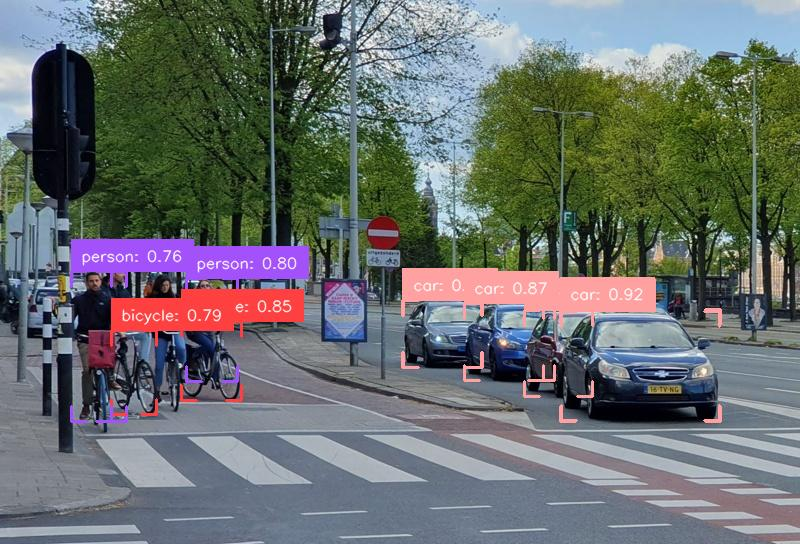

**1) Bounding Box**
- 객체가 위치한 영역을 둘러싸는 사각형
- 일반적으로 중심 좌표 (x, y), 너비 w, 높이 h로 위치를 표현

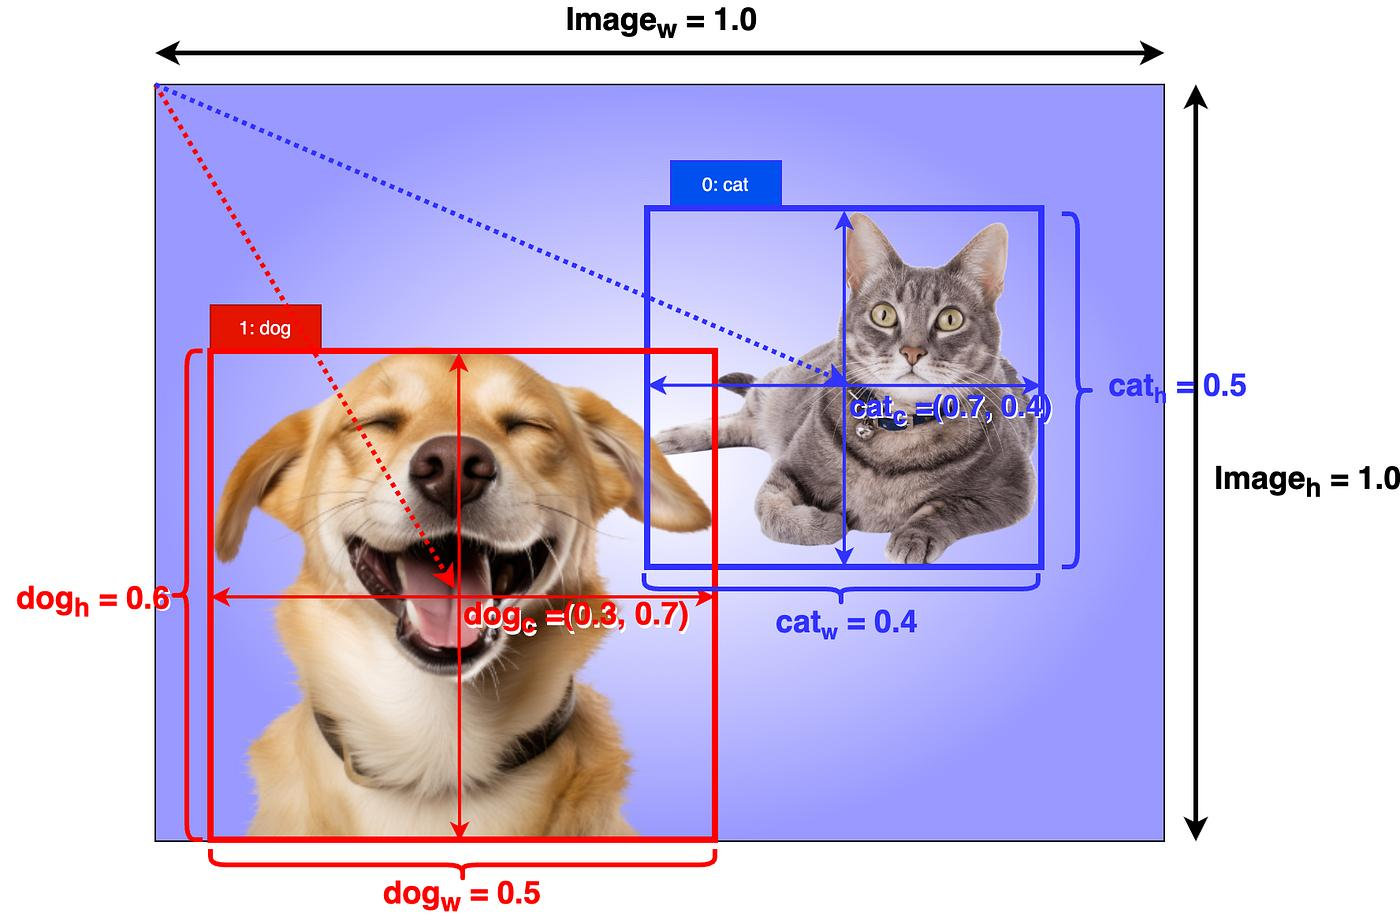

**2) 모델 적용 방식**
- CNN으로 Feature Map을 얻고 그 위에 두 개의 head를 올리는 구조
   - Classification Head: 객체의 종류 예측 (사람, 자동차, 강아지 등)
   - Regression Head: Bounding Box의 위치 좌표와 크기 예측
- 대표 모델: YOLO, Faster R-CNN, SSD

### 2-3. 이미지 캡셔닝 (Image Captioning)
- 이미지의 내용을 자연어 문장으로 표현하는 작업
- 객체를 찾는 데서 끝나지 않고 객체 간의 관계와 행동까지 파악

**1) 모델 적용 방식: CNN과 RNN**
- CNN: 이미지에서 객체 및 시각적 특징 추출
- RNN: 추출한 특징을 바탕으로 이전에 생성한 단어를 활용해 다음 단어를 순서대로 생성

**2) 이미지 캡셔닝 단계**
- ① CNN(Encoder, ResNet-101)을 이용한 특징 추출
- ② Attention Network를 이용한 단어 생성: 현재 생성하려는 단어와 관련된 이미지 영역에 더 높은 가중치 부여 (예: '사람' 생성 시 사람 영역에 집중)
- ③ RNN을 이용하여 문장 완성

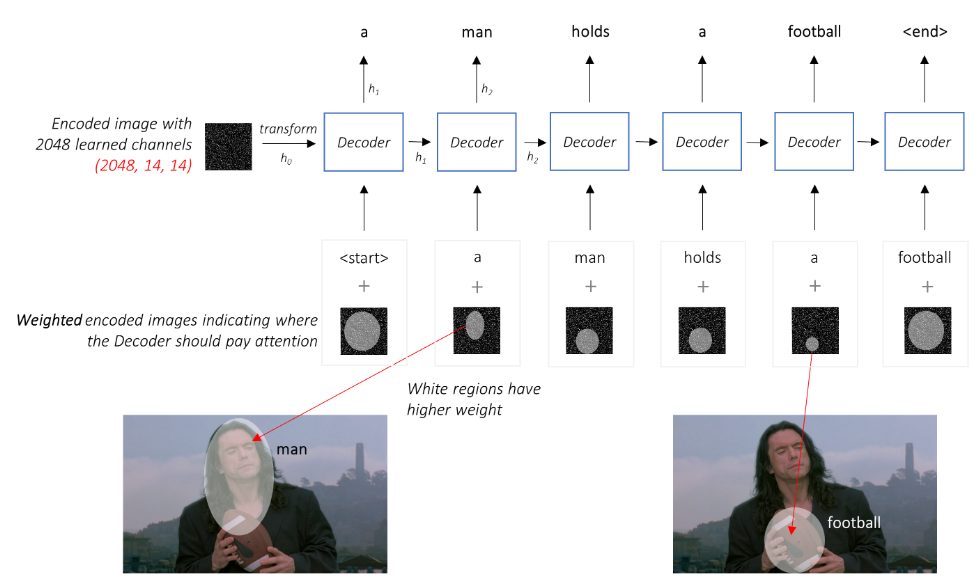

> CNN 세 줄 요약
> - (Conv + Pool)의 반복으로 특징을 학습
> - FC Layer를 적용하여 이미지를 분류
> - (Conv + Pool)에 어떤 방법을 적용하느냐에 따라 성능이 달라짐

## 3. 과거를 기억하는 신경망: RNN (Recurrent Neural Network)

### 3-1. 순차(Sequence) 데이터

**1) 개념**
- 데이터의 순서가 의미를 갖는 데이터로, 순서를 바꾸면 정보가 달라지는 데이터

**2) 세부 분류**
| 기준 | 구분 | 설명 | 예시 |
|---|---|---|---|
| 순서의 기준 | 시간적 순차 데이터 | 시간 순 | 주가, 기온 |
| | 비시간적 순차 데이터 | 시간 외 기준 (위치, 순번) | 문장 내 단어, DNA 염기서열 |
| 자료형 | 수치형 | 값의 크기와 거리에 의미 O | 음성, 비디오 |
| | 범주형 | 값의 크기와 거리에 의미 X | 웹 클릭 로그, 구매 이력 |

**3) 정형 데이터 vs 순차 데이터**
| 비교 관점 | 정형 데이터 | 순차 데이터 |
|---|---|---|
| 순서를 섞으면? | 의미 그대로 | 의미가 달라짐 → 요소의 순서의존성 |
| 샘플 간 관계 | 상호독립적 | 상호의존적 (이전 시점이 현재 시점에 영향) → 자기상관성 |
| 예시 | 고객 정보 데이터 | 주가, 문장 |

- 정형 데이터: 고객 A, B, C 행 순서를 바꿔도 의미 변화 없음
- 순차 데이터: "개가 사람을 물었다" → "사람이 개를 물었다"는 완전히 다른 의미

> 기존 머신러닝 기법(회귀, 결정트리, SVM)은 정형 데이터를 전제로 설계되어 순차 데이터 처리에 한계 → RNN 필요


### 3-2. RNN의 구조와 원리

**1) 구조**

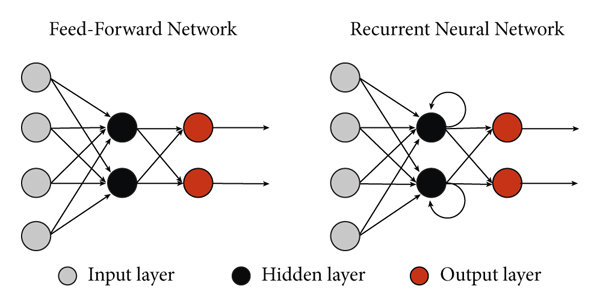
- 기존 신경망과 비교했을 때 가장 큰 차이점은 은닉층에 순환 구조가 존재한다는 것

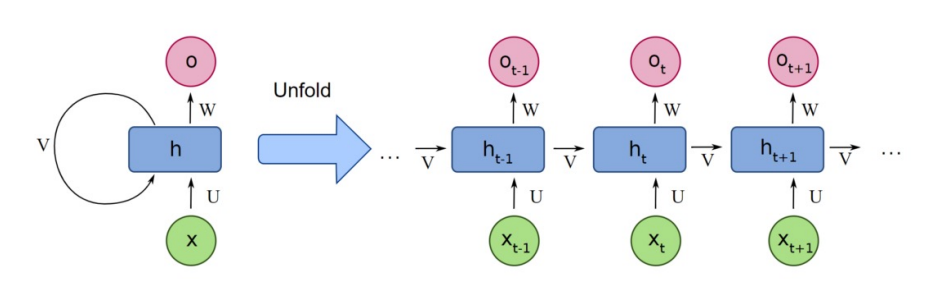

| 구성 요소 | 역할 |
|---|---|
| 입력층 ($x$) | 각 시점 t에 들어오는 입력 데이터 $x_t$를 받음 |
| 은닉층 ($h$) | 현재 입력 $x_t$와 이전 은닉 상태 $h_{t-1}$을 함께 받아 새로운 은닉 상태 $h_t$ 생성 |
| 출력층 ($o$) | 은닉 상태 $h_t$를 바탕으로 시점 t의 결과 $o_t$ 출력 |
| 입력 가중치 ($U$) | 입력 $x_t$를 은닉층으로 보낼 때 붙는 가중치 |
| 순환 가중치 ($V$) | 이전 은닉 상태 $h_{t-1}$을 현재 은닉층으로 보낼 때 붙는 가중치 |
| 출력 가중치 ($W$) | 은닉 상태 $h_t$를 출력 $o_t$로 바꿀 때 붙는 가중치 |

**2) 원리**
- 매 시점마다 현재 입력값과 이전 은닉 상태를 이용해 현재 은닉 상태를 계산하고, 그 결과를 다음 시점으로 넘겨줌
- 은닉 상태 계산: $h_t = \tanh(Ux_t + Vh_{t-1} + b)$ ($b$: 편향)
- 출력 계산: $o_t = f(Wh_t + c)$
   - $f$: 이진 분류는 시그모이드, 다중 분류는 소프트맥스 / $c$: 편향
- U, V, W는 모든 시점에서 같은 값을 사용 (가중치 공유)

- 예시: "나는 / 밥을 / 먹었다"
   - t=1: "나는" 입력 처리, 은닉 상태로 다음 은닉층에 전달
   - t=2: "나는" + "밥을" 정보 저장
   - t=3: 문장 전체 맥락이 $h_3$에 요약되고 활성화함수를 거쳐 최종 출력

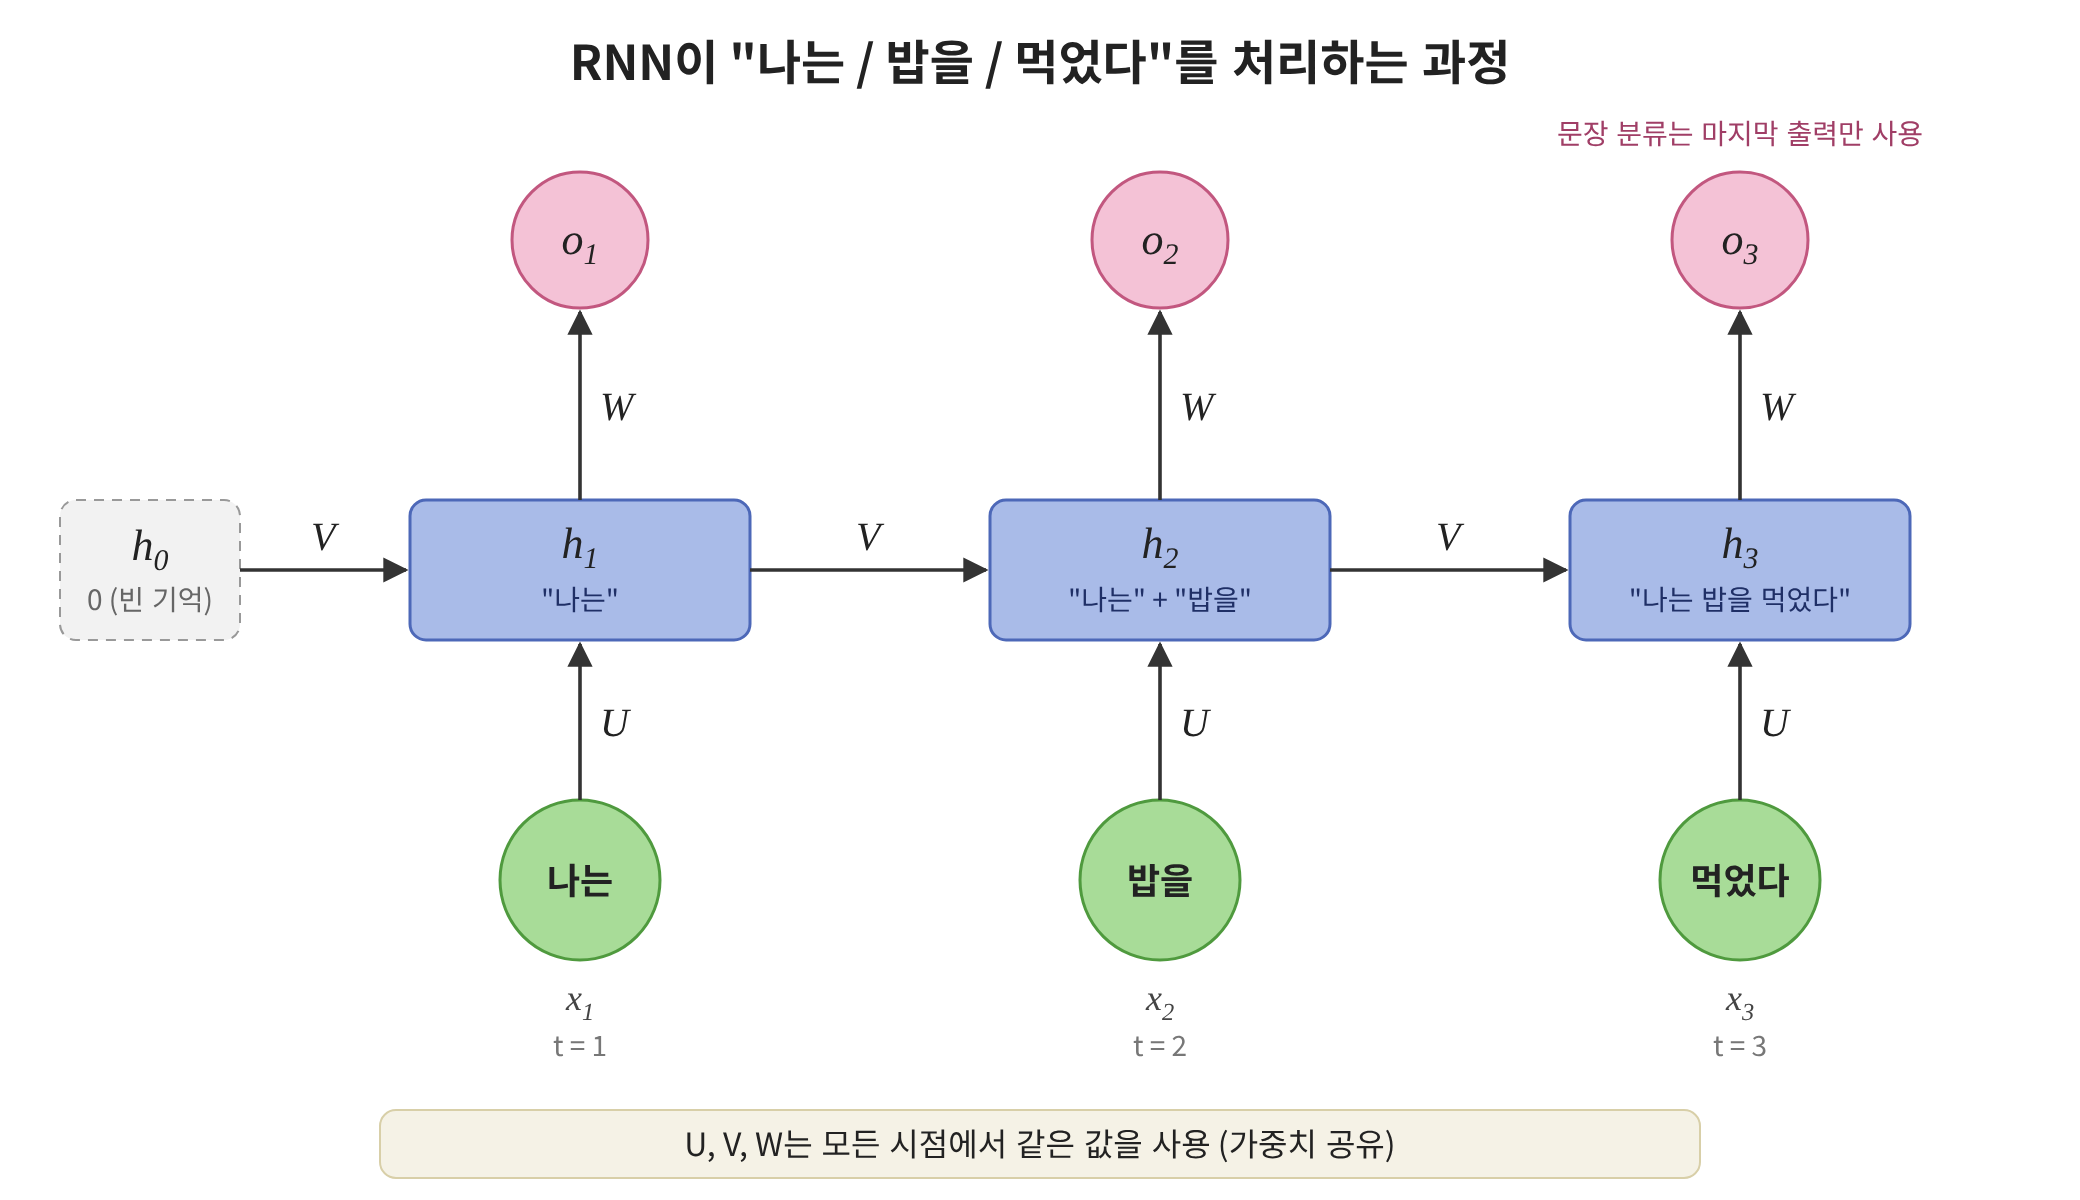

**3) RNN 아키텍처**
| 구조 | 내용 | 활용 예 |
|---|---|---|
| One to Many | 하나의 입력에서 시퀀스 출력 | 이미지 캡셔닝 |
| Many to One | 시퀀스 입력에서 하나의 값 출력 (전체를 읽은 후 최종 판별) | 스팸 메일 분류, 감성 분류 |
| Many to Many (동기식) | 매 시점마다 즉각 출력 | 개체명 인식 등 태깅 |
| Many to Many (비동기식) | 전체 입력을 끝까지 읽은 뒤 한 번에 출력 | 기계 번역, 요약 |

### 3-3. RNN의 한계 및 장기 의존성 문제

**1) 시간에 따른 역전파 (BPTT, Back Propagation Through Time)**
- RNN은 순전파로 시퀀스를 처리한 뒤, 시간을 거슬러 올라가며 오차를 전파하여 가중치 기울기를 누적 계산
- chain rule에 의해 한 시점을 거슬러 갈 때마다 다음 값이 곱해짐

$$
\frac{\partial h_t}{\partial h_{t-1}} = \text{diag}(g'(a_t)) \times V
$$

- 같은 순환 가중치 V를 모든 시점이 공유 → 같은 값이 계속 곱해지는 등비수열 형태 (k시점 전까지 가면 $V^k$ 꼴)

**2) RNN의 세 가지 한계**

**(1) 기울기 소실 (Vanishing Gradients)**
- 역전파 과정에서 기울기가 과거 시점으로 갈수록 0에 가까워지는 현상
- 원인: 곱해지는 값 < 1 (tanh 미분값은 최대 1, 대부분 1보다 작음 / V가 1보다 작으면 소실)
- 기본 RNN에서는 기울기 폭주보다 훨씬 자주 발생
- 예: 가까운 3단어가 기울기의 약 88%를 차지하는 반면, 정답에 필요한 7시점 전 단어의 몫은 약 0.4%

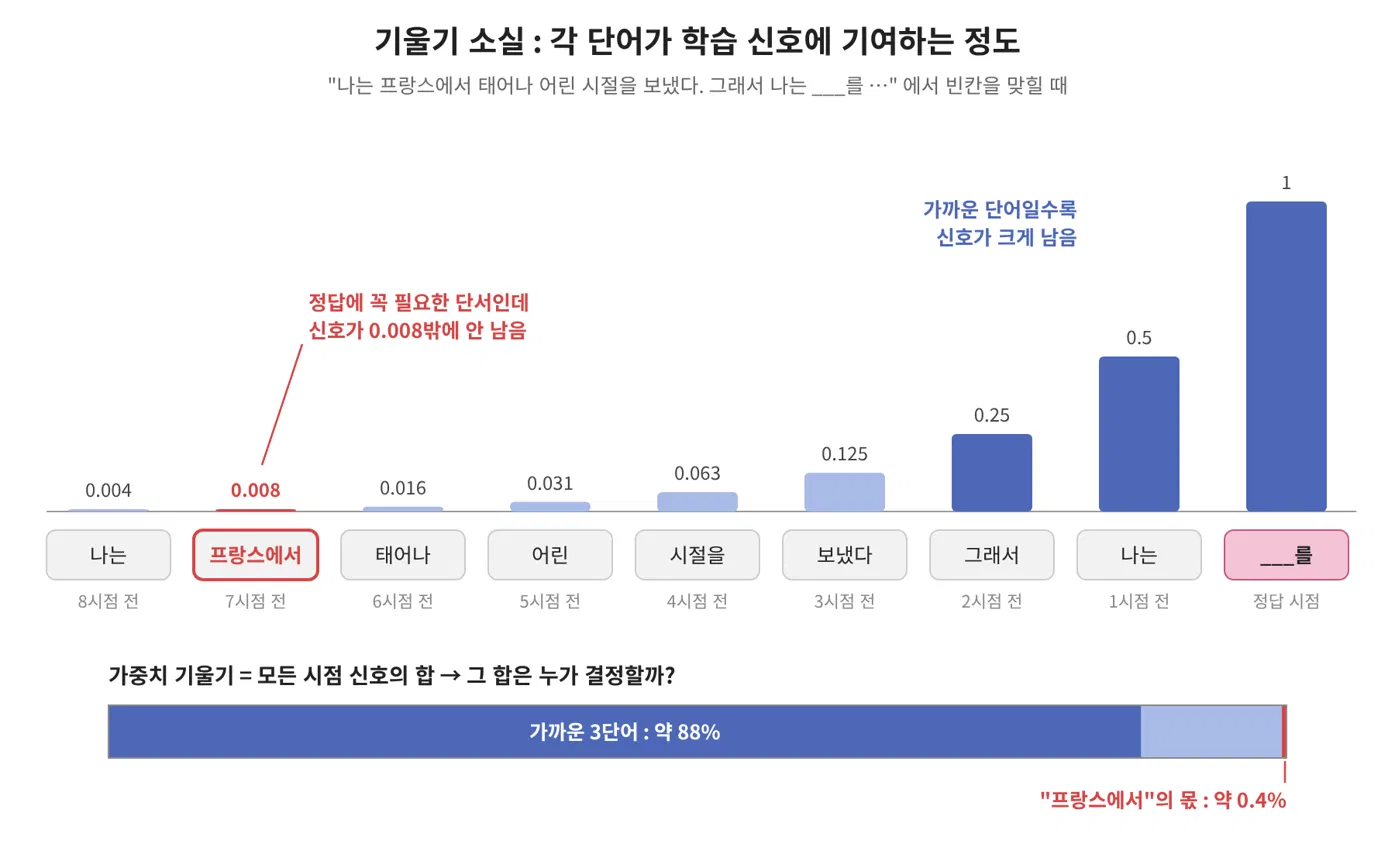

**(2) 기울기 폭주 (Exploding Gradients)**
- 역전파 과정에서 기울기가 과거 시점으로 갈수록 매우 커지는 현상
- 원인: 곱해지는 값 > 1
- 가중치가 크게 튀면서 오차가 치솟거나 진동, 심하면 NaN이 발생해 학습 중단
- 예: 시점마다 1.5배씩 곱해지면 8시점 전 신호가 25.6까지 커짐

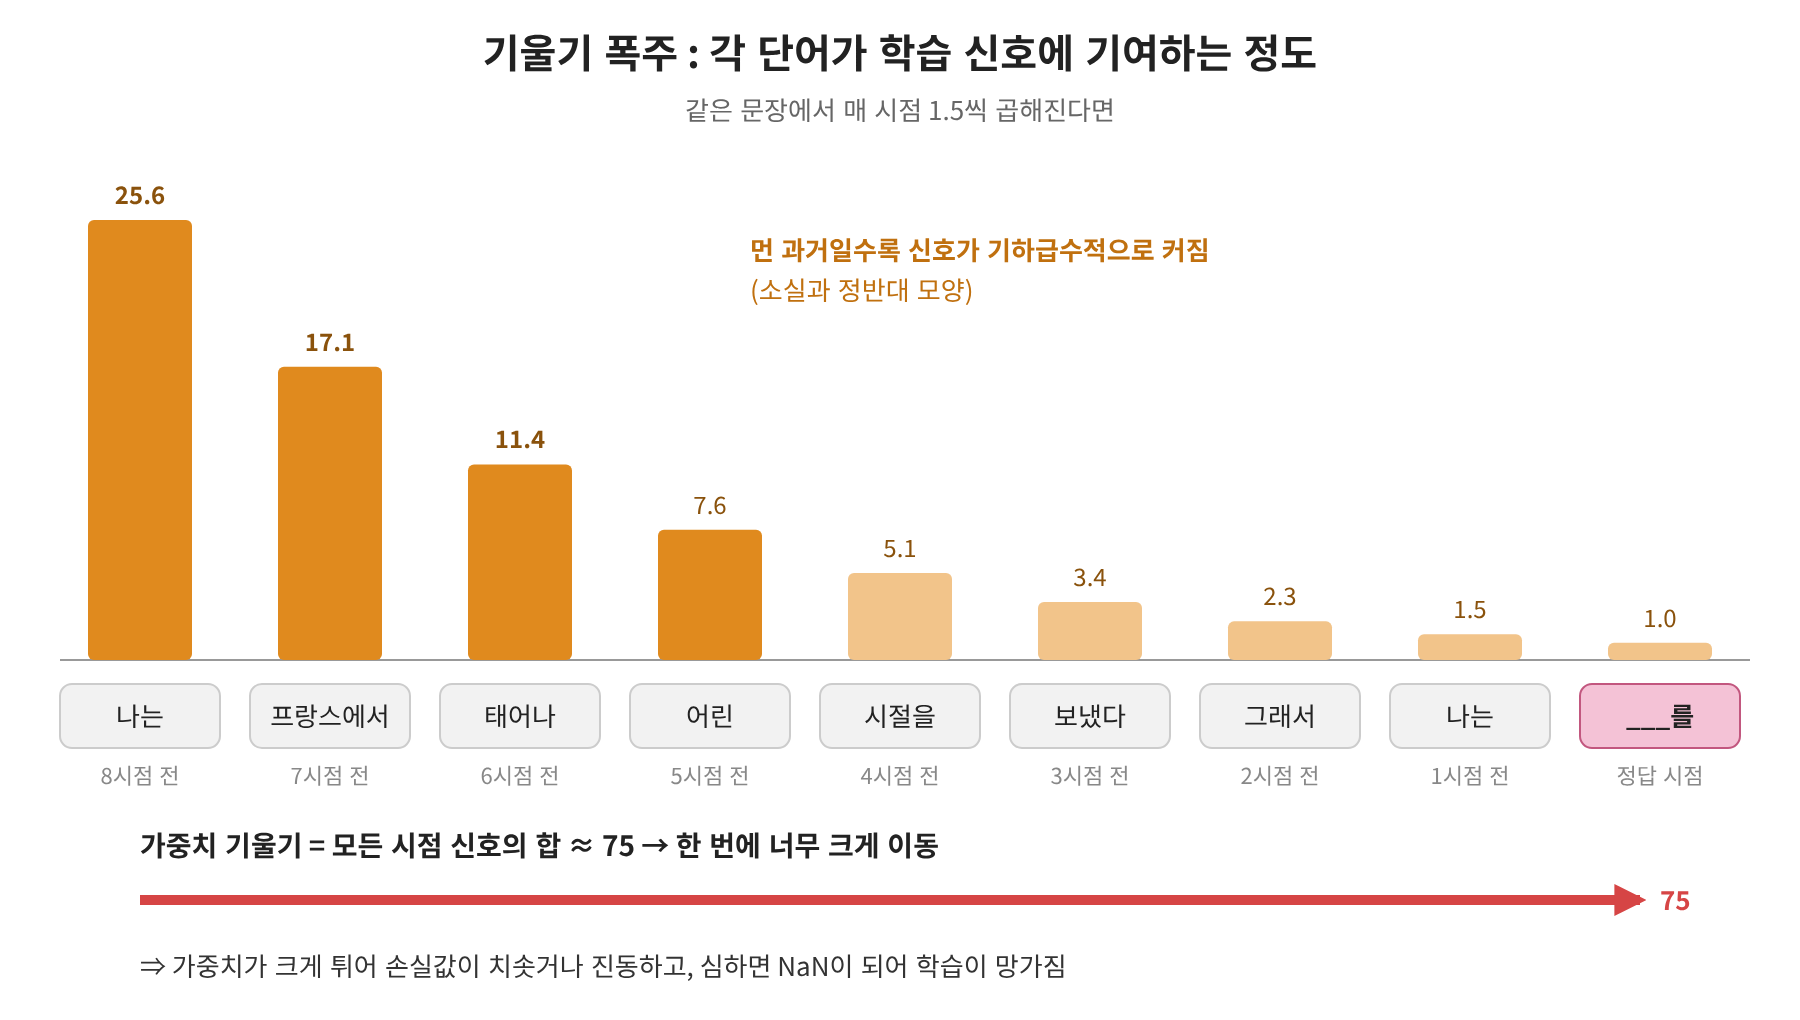

**(3) 느린 훈련 시간**
- 시점을 하나씩 순서대로만 계산할 수 있어 시퀀스 길이에 비례해 계산 시간 증가
- 역전파를 위해 모든 시점의 은닉 상태를 저장해야 해 메모리 부담이 큼
- CNN은 각 위치를 독립적으로 계산해 병렬 처리가 가능한 반면, RNN은 앞 시점 결과가 있어야 다음 계산 가능

**3) 장기 의존성 문제 (Long-Term Dependency Problem)**
| 한계 | 무슨 일이 일어나나 | 결과 |
|---|---|---|
| 기울기 소실 | 먼 과거로 갈수록 학습 신호가 0에 가까워짐 | 먼 과거 정보 반영 안 됨 |
| 기울기 폭주 | 먼 과거로 갈수록 신호가 폭발해 학습이 불안정 | 먼 관계를 안정적으로 학습하지 못함 |
| 느린 훈련 시간 | 시퀀스가 길어질수록 학습 비용 증가 | 먼 관계 학습에 많은 비용 필요 |

> 시퀀스에서 관련된 정보가 멀리 떨어져 있을수록 RNN이 그 관계를 기억하고 학습하지 못하는 문제로 귀결
> <br> 중요한 정보는 오래 기억하고 불필요한 정보는 잊는 메모리 구조 필요 (LSTM & GRU)


## 4. 똑똑하게 기억하고 잊는 법: LSTM & GRU

### 4-1. LSTM & GRU 개요
- 두 모델 모두 게이트(gate)를 활용해 무엇을 기억하고 무엇을 기억하지 않을지 결정

| 구분 | LSTM | GRU |
|---|---|---|
| 상태 | 셀 상태(장기 기억) + 은닉 상태(단기 기억 & 출력) (2개) | 은닉 상태 (1개) |
| 게이트 | Forget · Input · Output (3개) | Update · Reset (2개) |
| 핵심 아이디어 | 장기·단기 기억을 분리 | 기억과 출력을 통합 |
| 장점 | 정교한 기억 관리 | 단순하고 빠름 |
| 단점 | 복잡하고 계산량 많음 | 정교함이 떨어짐 |

### 4-2. 게이트(Gate)로 정보의 흐름을 제어하다: LSTM

**1) LSTM 구조**

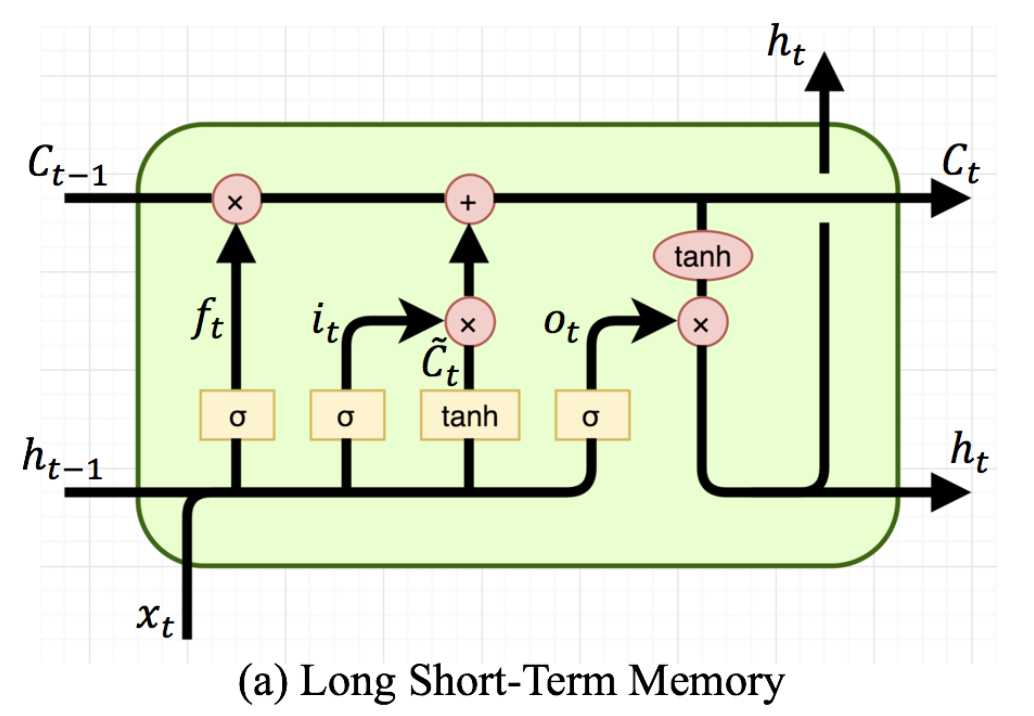

- 셀 상태(Cell State, 장기 기억): 구조도 맨 위를 가로지르는 선으로, 시점을 따라 큰 변화 없이 흘러감
- 게이트가 정보를 빼거나(잊기) 더해서(기억하기) 조절

> 기억할 내용과 잊어버릴 내용을 선택해, 중요한 정보를 오래 가져갈 수 있음

**RNN과의 주요 차이**
| 구분 | RNN | LSTM |
|---|---|---|
| 순환되는 상태 | 은닉 상태 h (1개) | 셀 상태 C + 은닉 상태 h (2개) |
| 역할 | h 하나가 기억과 출력을 모두 담당 | C = 장기 기억, h = 단기 기억이자 출력 |
| 기억 갱신 | 매 시점 통째로 덮어씀 | 게이트로 선택적으로 지우고 더함 |

**2) 단계별 LSTM 수식**

| 단계 | 역할 | 수식 | 설명 |
|---|---|---|---|
| Step 1. Forget gate | 무엇을 잊을까? | $f_t = \sigma(W_f \cdot [h_{t-1}, x_t] + b_f)$ | 이전 셀 상태에 곱해질 0~1 값 ($f_t \approx 1$: 유지, $f_t \approx 0$: 완전히 잊음) |
| Step 2. Input gate | 무엇을 새로 기억할까? | $i_t = \sigma(W_i \cdot [h_{t-1}, x_t] + b_i)$, $\tilde{C}_t = \tanh(W_C \cdot [h_{t-1}, x_t] + b_C)$ | $i_t$: 새 정보 반영 정도(0~1), $\tilde{C}_t$: 추가할 후보 정보(-1~1) |
| Step 3. Final memory cell | 기억 업데이트 | $C_t = f_t \odot C_{t-1} + i_t \odot \tilde{C}_t$ | Step 1에서 남긴 이전 기억 + Step 2에서 고른 새 정보 |
| Step 4. Output gate | 무엇을 내보낼까? | $o_t = \sigma(W_o \cdot [h_{t-1}, x_t] + b_o)$, $h_t = o_t \odot \tanh(C_t)$ | 셀 상태를 -1~1로 정리한 뒤 필요한 부분만 출력 |

**3) LSTM의 장단점**
- 장점
   - 셀 상태의 덧셈 구조 덕분에 기울기가 먼 과거까지 전달 → 기울기 소실 완화
   - 중요한 정보는 남기고 불필요한 정보는 지움 → 장기 의존성 학습 가능
   - 문장 번역, 음성 인식 등 긴 시퀀스 과제에서 RNN보다 좋은 성능
- 단점
   - 계산량이 많아 학습이 느리고 메모리 사용이 많음
   - 여전히 시점을 순서대로 계산해야 해 병렬 처리 불가
   - 기울기 소실을 완화했을 뿐 완전히 해결하지는 못함

> 더 단순한 구조인 GRU 등장의 배경

### 4-3. 더 단순하고 효율적인 구조: GRU (Gated Recurrent Unit)

**1) 정의**
- LSTM의 핵심 아이디어(게이트로 정보를 선택적으로 기억·삭제)는 유지하면서 구조를 단순하게 줄인 모델
- LSTM: 상태 2개, 게이트 3개 / GRU: 상태 1개, 게이트 2개

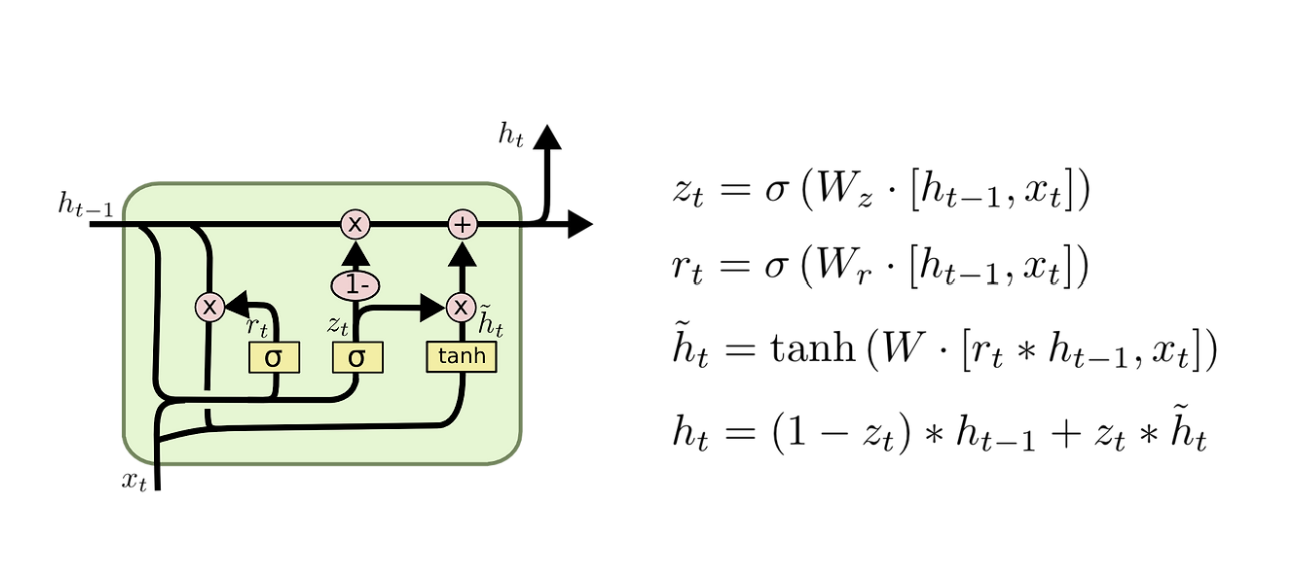

**2) LSTM과의 차이점**
- Forget gate와 Input gate를 Update gate 하나로 통합
   - Update gate $z_t$ 하나로 '과거 기억 : 새 정보' 비율을 한 번에 결정
- Reset gate 사용
   - 과거 기억을 얼마나 무시할지 먼저 정한 뒤 후보 정보 $\tilde{h}_t$ 생성
   - $r_t \approx 0$ → 과거를 거의 무시하고 현재 입력 위주로 새 정보 생성
- Output gate 없음: 은닉 상태 $h_t$를 그대로 출력
- Gate 수 3개 → 2개: 파라미터가 LSTM의 약 3/4 → 학습 시간 단축, 성능은 비슷하거나 과제에 따라 더 좋은 경우도 있음

| 구분 | LSTM | GRU |
|---|---|---|
| 기억 상태 | 셀 상태 + 은닉 상태 (2개) | 은닉 상태 (1개) |
| 잊기 / 기억하기 | Forget gate, Input gate 따로 | Update gate 하나로 |
| 과거 무시 여부 | 별도 게이트 없음 | Reset gate |
| 출력 조절 | Output gate | 없음 (은닉 상태 그대로 출력) |
| 게이트 수 | 3개 | 2개 |
| 파라미터 | 많음 | LSTM의 약 3/4 |

**3) GRU의 장단점 (vs. LSTM)**
| 구분 | 장점 | 단점 |
|---|---|---|
| 구조 | 상태 1개, 게이트 2개로 단순 → 이해·구현이 쉬움 | 장기 기억과 출력을 분리하지 못함 |
| 속도 | 파라미터가 적어 학습이 빠르고 메모리 사용이 적음 | - |
| 데이터 | 데이터가 적을 때도 학습이 안정적 | 데이터가 많고 복잡한 과제에서는 LSTM이 더 나을 수 있음 |
| 기억 관리 | Update gate 하나로 간단히 처리 | 잊는 양과 더하는 양을 따로 조절할 수 없어 정교함이 떨어짐 |
| 성능 | 많은 과제에서 LSTM과 비슷한 성능 | 항상 LSTM보다 낫다고 단정할 수 없음 |

### 4-4. LSTM vs GRU: 언제 무엇을 선택할까?
- 두 모델은 우열 관계가 아니라 정교함(LSTM)과 효율(GRU) 사이의 선택
- 실제 비교 연구에서도 많은 과제에서 두 모델의 성능은 비슷함

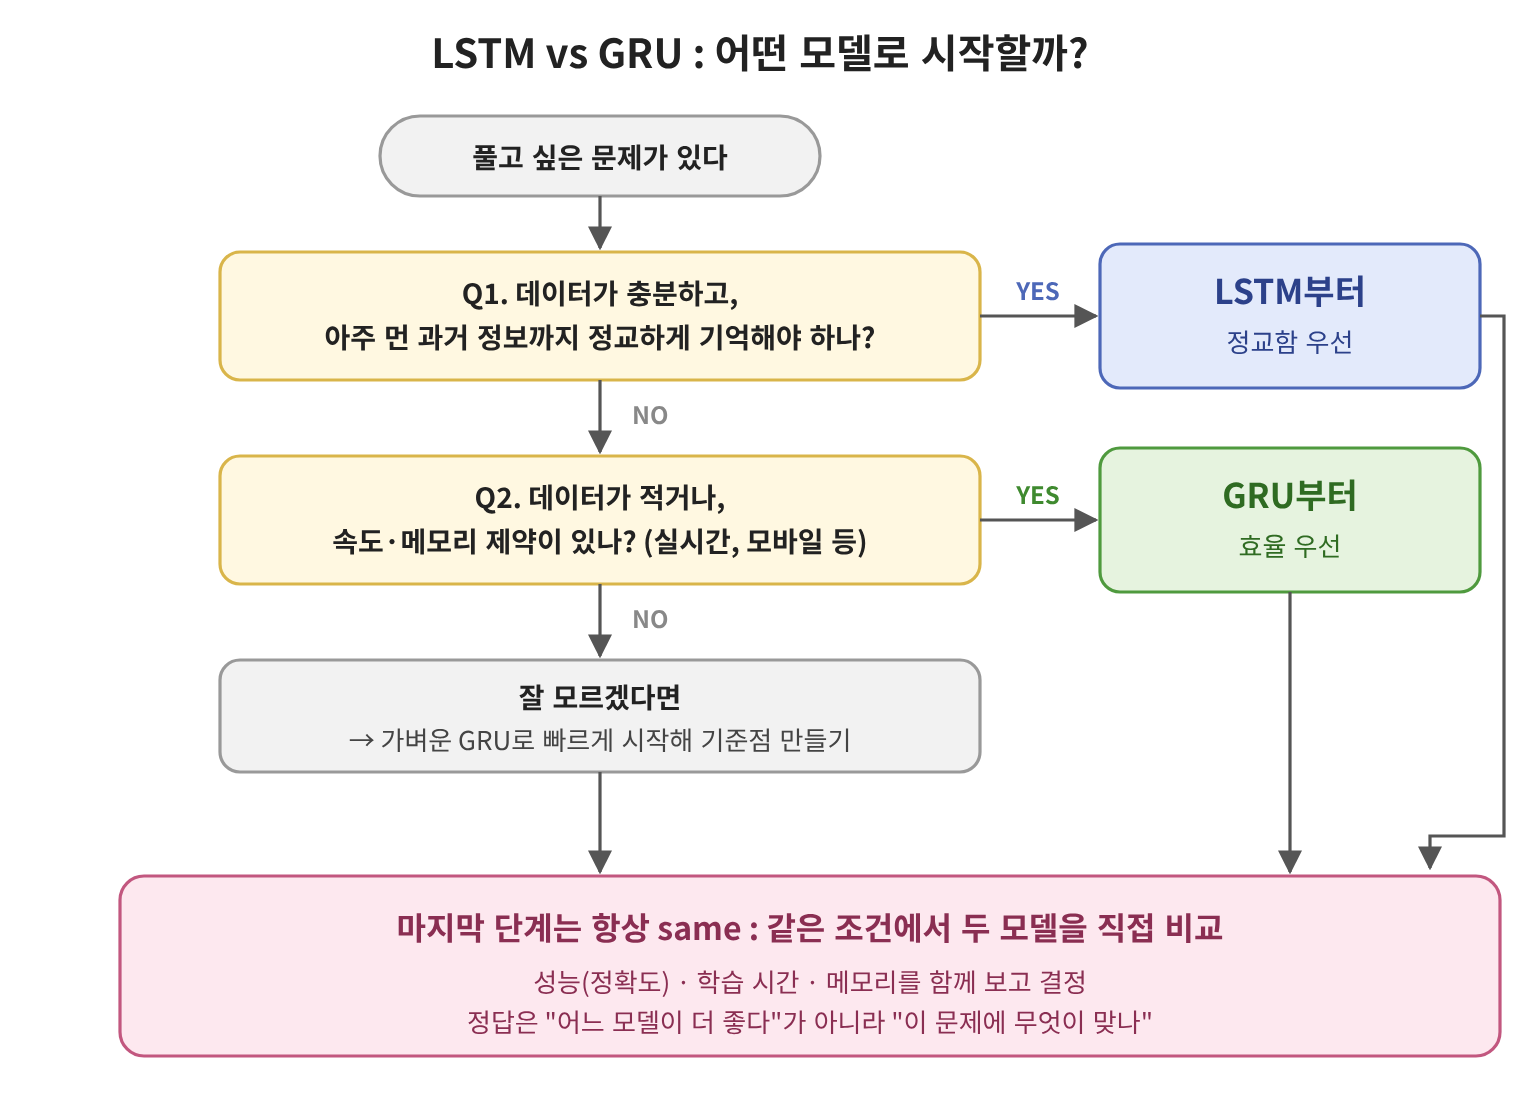

> 문제 상황에 따라 적합한 모델이 다름


**2) Apriori 알고리즘 소개**
- (개념) 상위 조합에서부터 차례로 스캔하면서 특정 조합이 자주 발생하지 않는다면 이의 결과물로 탄생한 후속 조합들까지 모두 후보에서 배제하는 방식의 알고리즘
- (장점) Apriori 알고리즘을 활용하면 하나의 조합만 검사하고도 이에서 파생된 다른 조합들까지 후보에서 배제할 수 있게 되므로 시간과 연산량을 효과적으로 줄일 수 있음

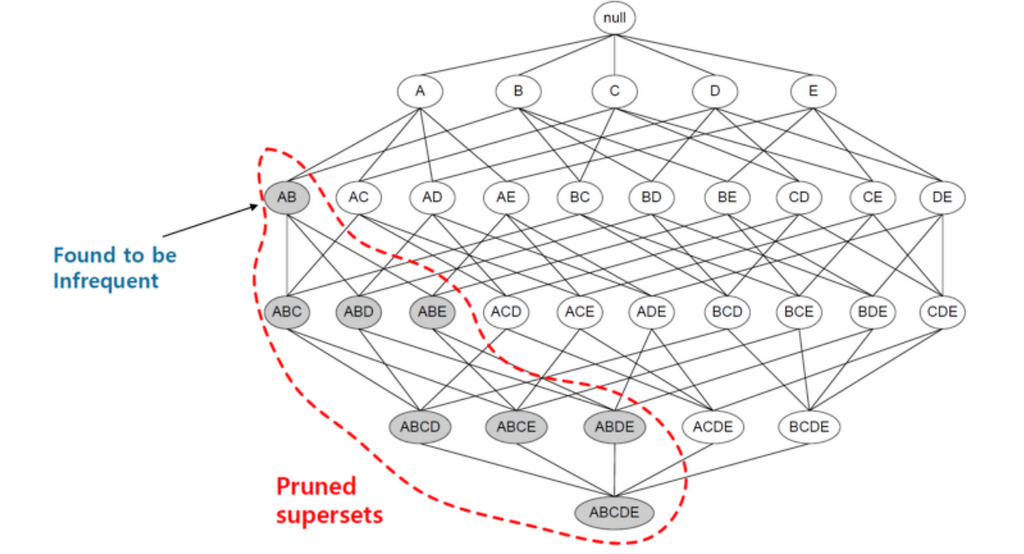

## 5. 문장을 입력받아 문장을 출력하다: Seq2Seq

### 5-1. Seq2Seq의 기본 구조: 인코더와 디코더

**1) 정의**
- Sequence-to-Sequence: 입력 시퀀스를 받아 다른 시퀀스를 출력하는 모델
- 입력과 출력의 길이가 서로 달라도 됨 → 기존 RNN과의 가장 큰 차이 (예: "I am a student"(4단어) → "je suis étudiant"(3단어))
- RNN 아키텍처 중 "Many to Many"를 두 개의 RNN(LSTM)으로 나눠 구현한 구조
- 활용 분야: 기계 번역, 챗봇(질문 → 답변), 문서 요약, 음성 인식

**2) 특징**

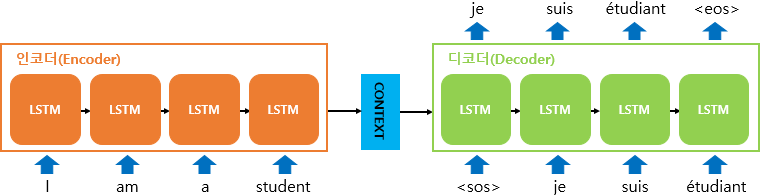

- 인코더(Encoder)와 디코더(Decoder) 두 개의 모듈로 구성
   - 인코더: 입력 문장을 읽고 하나의 컨텍스트 벡터로 압축
   - 컨텍스트 벡터(Context Vector): 인코더와 디코더를 잇는 다리이자 압축된 정보
   - 디코더: 컨텍스트 벡터를 받아 출력 문장을 한 단어씩 생성
- 내부 셀로는 주로 LSTM 또는 GRU 사용 (장기 의존성 문제 때문)

> 읽고(인코더) → 요약해서 넘기고(컨텍스트 벡터) → 다시 써낸다(디코더)

**3) 인코더**
- 입력 문장의 모든 단어를 순서대로 읽고, 문장 전체의 정보를 하나의 벡터(컨텍스트 벡터)로 압축하는 LSTM
- 작동 원리
   - ① 단어 토큰화: 입력 문장을 단어 단위로 나눔 ("I", "am", "a", "student")
   - ② 임베딩: 각 단어를 숫자 벡터로 변환
   - ③ LSTM 셀에 한 단어씩 입력: 은닉 상태가 다음 시점으로 전달되며 정보 누적
   - ④ 마지막 시점의 은닉 상태 = 문장 전체 정보가 담긴 컨텍스트 벡터 → 디코더로 전달
- 인코더는 중간 시점의 출력은 사용하지 않고, 마지막 은닉 상태만 디코더로 넘김

**4) 디코더**
- 컨텍스트 벡터를 받아 출력 문장을 한 단어씩 순서대로 생성하는 LSTM
- 작동 원리
   - ① 컨텍스트 벡터를 디코더 LSTM의 첫 은닉 상태로 받음
   - ② 시작 신호 `<sos>`를 첫 입력으로 넣음
   - ③ 매 시점 softmax로 다음 단어의 확률 계산 → 가장 확률이 높은 단어 선택(argmax)
   - ④ 방금 예측한 단어를 다음 시점의 입력으로 다시 넣음 (예: `<sos>` → "je" → "suis" → "étudiant")
   - ⑤ 종료 신호 `<eos>`가 나오면 생성 종료

**5) 컨텍스트 벡터**
- 인코더가 입력 문장 전체를 읽고 만든 문장 요약 벡터
- 인코더 LSTM의 마지막 시점 은닉 상태 (LSTM이면 셀 상태도 함께 넘김)
- 인코더와 디코더를 연결하는 유일한 통로
- 차원 설정
   - 컨텍스트 벡터의 크기 = 인코더 LSTM의 은닉 상태 크기 → 사람이 정하는 하이퍼파라미터
   - 디코더 LSTM의 은닉 상태 크기도 같은 값으로 맞춰야 바로 이어받을 수 있음
   - 차원이 크면 더 많은 정보를 담지만 계산량 증가, 과적합 위험 / 작으면 빠르지만 긴 문장의 정보를 다 담지 못함

### 5-2. Seq2Seq의 한계: 병목 현상 (Bottleneck)

**1) 정의**
- 인코더가 입력 문장 전체를 '고정된 크기의 컨텍스트 벡터 하나'에 압축하면서 정보가 좁은 통로에 막혀 손실되는 현상

**2) 설명**
- 5단어든 50단어든 같은 크기(예: 512차원)에 담아야 함 → 긴 문장일수록 정보를 다 담지 못하고 손실
- 앞 단어는 여러 시점을 거치며 희미해짐 → 장기 의존성 문제가 여전히 존재

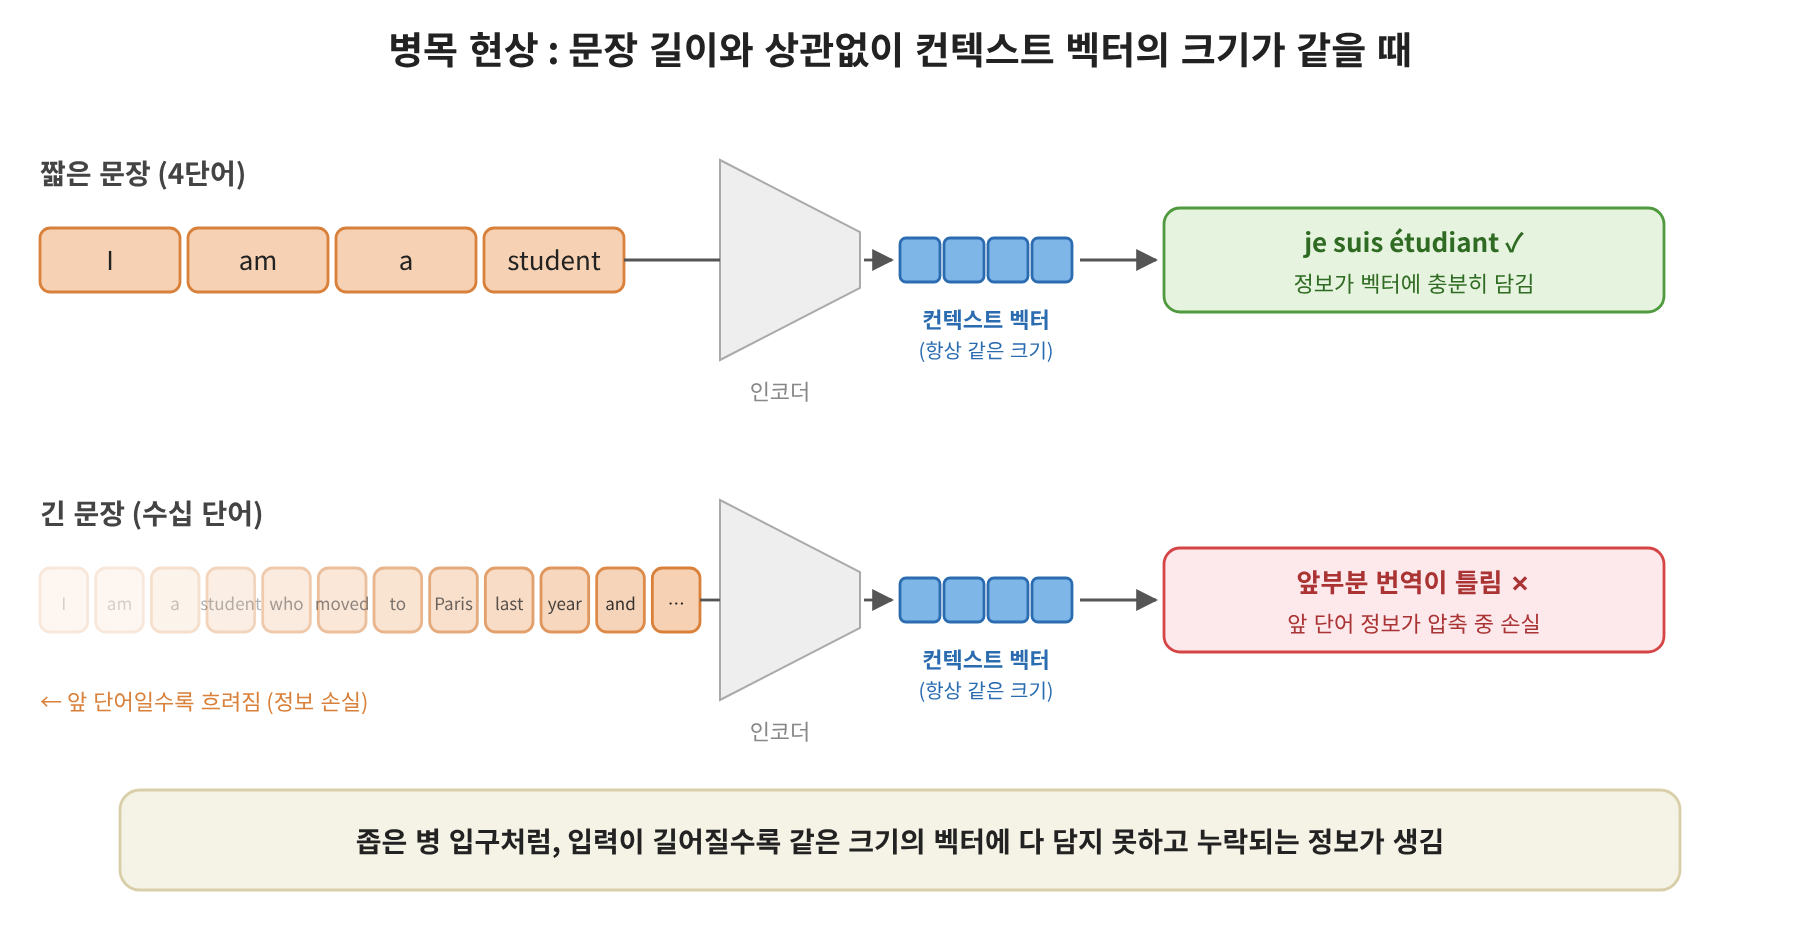

**3) 예시**
- 짧은 문장: "I am a student" → 정보가 적어 컨텍스트 벡터에 충분히 담김 → 번역 정확
- 긴 문장: "I am a student who moved to Paris last year and …" (수십 단어) → 앞부분 정보가 손실되어 주어나 앞 내용을 틀리게 번역
- 실제 연구에서도 입력 문장이 길어질수록 기본 Seq2Seq의 번역 품질이 급격히 떨어지는 것으로 나타남

> 고정된 크기의 컨텍스트 벡터에 모든 정보를 압축하기 때문에 병목 현상이 발생하며, 특히 긴 입력 시퀀스일수록 정보 손실과 성능 하락이 심각
> <br> 이 한계를 해결한 것이 Attention